# Week 10 - Neural Networks

Learning contents:
1. Detailed example: Two-layer MLP for regression
    - Forward pass: Calculate the values of $z_1$, $z_2$, and $y$
    - Compute the mean squared error
    - Using backpropagation, compute the gradient of the error w.r.t the weights $w^{(2)}_2$ and $w^{(1)}_{2,2}$ 
    - Compute the updated weights for $w^{(2)}_2$ and $w^{(1)}_{2,2}$ 
2. PyTorch: 2-layer MLP for classification
    - Create and train a 2-layer MLP

# 1) Detailed example: Two-layer MLP for regression
We'll be working through a forward and back-propagation example in all its details for a 2-layer MLP for regression. Our network has the following structure:

![](two-layer-nn.svg)

Where 
    $$
    z_j = \text{ReLU}\left(a_j \right)
    \qquad
    a_j = \sum_i w^{(1)}_{ij} x_i
    \qquad
    y_j = \sum_i w^{(2)}_{ij} z_i
    $$
and the biases 
    $$
    x_0 = z_0 = 1
    $$

Suppose, we have the weights
    $$
    \mathbf{W}^{(1)} = \left[ 
        \begin{matrix}
        0.1 & 0.2\\
        -1.1 & 1.2\\
        -2.1 & 2.2
        \end{matrix}
    \right]
    \qquad
    \mathbf{w}^{(2)} = \left[ 
        \begin{matrix}
        -0.1\\
        1.1 \\
        2.2
        \end{matrix}
    \right]
    $$
Notice that the bias weights are included in the weight matrix. Relating it to the drawing, we have $w^{(1)}_{0,1} = 0.1$ and $w^{(1)}_{1,2} = 1.2$. The biases drawn as $b_0^{(1)}$ and $b_0^{(2)}$ in the figure are exactly the weight-matrix entries: $b_0^{(1)}$ **is** $w^{(1)}_{0,1}$, and $b_0^{(2)}$ **is** $w^{(2)}_0$.

Moreover, we are given an input
    $$
    \mathbf{x} = \left[ 
        \begin{matrix}
        0.1 \\
        0.2
        \end{matrix}
    \right]
    $$
    
Relating these to the drawing, we have $w^{(1)}_{1,2} = 1.2$ and $x_1 = 0.1$

## 1.1) Forward pass: Calculate the values of $z_1$, $z_2$, and $y$

Use the values and formulas given above, as well as information about the ReLU activation function given in lecture 19 slide 9 to determine the values. 

In [112]:
import numpy as np  # initialize NumPy/OpenMP before PyTorch in Jupyter
import torch

# Given data (from the description above)
x = torch.tensor([
    [0.1],
    [0.2]
])

W1 = torch.tensor([
    [ 0.1, 0.2],
    [-1.1, 1.2],
    [-2.1, 2.2]
], requires_grad=True)

w2 = torch.tensor([
    [-0.1],
    [ 1.1],
    [ 2.2]
], requires_grad=True)


def augment(v):
    """Prepend a bias unit (a row of 1s) to the column vector v.
    e.g. shape (2, 1) -> (3, 1)."""
    return torch.cat([torch.ones(1).unsqueeze(0), v])


# TODO: compute the pre-activations a = W1^T @ augment(x),
#       the hidden activations z = ReLU(a), and the output y.
#       Then print z_1, z_2 and y.
# a = ...
# z = ...
# y = ...

x_aug = augment(x)
a = W1.T @ x_aug
z = torch.relu(a)
y = w2.T @ augment(z)

print(x_aug)
print("a =", a)
print("z =", z)
print("y =", y)


tensor([[1.0000],
        [0.1000],
        [0.2000]])
a = tensor([[-0.4300],
        [ 0.7600]], grad_fn=<MmBackward0>)
z = tensor([[0.0000],
        [0.7600]], grad_fn=<ReluBackward0>)
y = tensor([[1.5720]], grad_fn=<MmBackward0>)


## 1.2) Compute the mean squared error
Suppose our target $t=2$.
Compute the error using the ½ sum-of-squares error $E = \tfrac12 (y-t)^2$ from Lecture 19, slide 17, eq. (8) — here for a single output and a single sample.

In [113]:
# Given target
t = torch.tensor([2])

# TODO: compute the error E = 1/2 * (y - t)**2  (see 1.2 above) and print it.
# E = ...

E = 0.5 * (y - t)**2
print(E)


tensor([[0.0916]], grad_fn=<MulBackward0>)


## 1.3) Using backpropagation, compute the gradient of the error w.r.t the weights $w^{(2)}_2$ and $w^{(1)}_{2,2}$ 
This corresponds to the bottom row of weights on the figure

To compute this, look at formulas 5.65 - 5.67 in the course book (Bishop) — these are **Lecture 20, "Error Backpropagation"**, eqs (11) $\delta_k = y_k - t_k$ [PRML 5.65], (12) $\delta_j = h'(a_j)\sum_k w_{kj}\delta_k$ [PRML 5.66] and (10) $\partial E_n/\partial w_{ji} = \delta_j z_i$ [PRML 5.67]; see also the worked "Error Backpropagation: Example/Solution" slides.

In [114]:
# TODO: use backpropagation to compute the gradient of the error w.r.t.
#       w^{(2)}_2 and w^{(1)}_{2,2}  (PRML 5.65-5.67 / Lecture 20).
# dEdy     = ...   # delta at the output (y - t)
# dEdw2_2  = ...   # dE/dw^{(2)}_2
# dEdw1_22 = ...   # dE/dw^{(1)}_{2,2}

dEdy = y - t
dEdw2_2 = dEdy * z[1]
hidden_delta_2 = dEdy * w2[2] * (a[1] > 0)
dEdw1_22 = hidden_delta_2 * x[1]

print("dE/dw^(2)_2 =", dEdw2_2)
print("dE/dw^(1)_(2,2) =", dEdw1_22)

# Check the hand calculation against PyTorch's gradients for all weights.
grad_W1, grad_w2 = torch.autograd.grad(E, (W1, w2), retain_graph=True)
print("dE/dW^1 =", grad_W1)
print("dE/dw^2 =", grad_w2)


dE/dw^(2)_2 = tensor([[-0.3253]], grad_fn=<MulBackward0>)
dE/dw^(1)_(2,2) = tensor([[-0.1883]], grad_fn=<MulBackward0>)
dE/dW^1 = tensor([[ 0.0000, -0.9416],
        [ 0.0000, -0.0942],
        [ 0.0000, -0.1883]])
dE/dw^2 = tensor([[-0.4280],
        [-0.0000],
        [-0.3253]])


## 1.4) Compute the updated weights for $w^{(2)}_2$ and $w^{(1)}_{2,2}$ 
Use a learning rate $\eta = 0.1$ 

You will want to use formula 5.43 in the course book to determine the updated weights — this is **Lecture 19/20, "Parameter optimization: Gradient descent"**, $w^{(\tau+1)} = w^{(\tau)} - \eta \nabla E$ [PRML 5.43].



In [115]:
lr = 0.1

# TODO: apply one gradient-descent step  w <- w - lr * dE/dw  (PRML 5.43)
#       to w^{(2)}_2 and w^{(1)}_{2,2}, and print the updated weights.
# w2_2_next  = ...
# w1_22_next = ...

w2_2_next = w2[2] - lr * dEdw2_2
w1_22_next = W1[2, 1] - lr * dEdw1_22

print(w2_2_next)
print(w1_22_next)


tensor([[2.2325]], grad_fn=<SubBackward0>)
tensor([[2.2188]], grad_fn=<SubBackward0>)


# 2) PyTorch: 2-layer MLP for classification
Luckily, there are some nice Deep Learning libraries out there, that make working with neural networks a pleasure.
The two most notable are [Tensorflow](https://www.tensorflow.org) and [PyTorch](https://pytorch.org). We'll be using the latter.

`torch` and `torchvision` are already installed in the Week 1 `slml` conda environment, so you should not need to install anything. If for some reason they are missing, you can fall back to `pip install torch torchvision` (fallback only — prefer the managed `slml` environment).

A key feature of these libraries is that they can handle the gradient computation for you.
Moreover, they have a lot of layer types and losses, that are easily composable to handle computation of complex neural networks.

We'll be working with the classic MNIST dataset, which we can easily get via PyTorch

In [116]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Note: run this notebook from its own directory (Exercises/10-neural-networks/)
# so that the relative path '../data' resolves to the Week 1 MNIST cache in
# Exercises/data/ and MNIST is NOT re-downloaded.
train_data = datasets.MNIST('../data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('../data', train=False, download=True, transform=transform)

train_loader = DataLoader(
    train_data,
    batch_size = 64,
    shuffle=True,
)

test_loader = DataLoader(
    test_data,
    batch_size = 64,
)

A few steps happened here:
1. The dataset (train and test) was downloaded 
1. We created a `DataLoader` for each data split. Using this, we get batches of data (64 examples per batch here)
1. We asked for the training data to be shuffled

Lets see what we get in a batch:

In [117]:
data, targets = next(iter(train_loader))
data.shape, targets.shape

(torch.Size([64, 1, 28, 28]), torch.Size([64]))

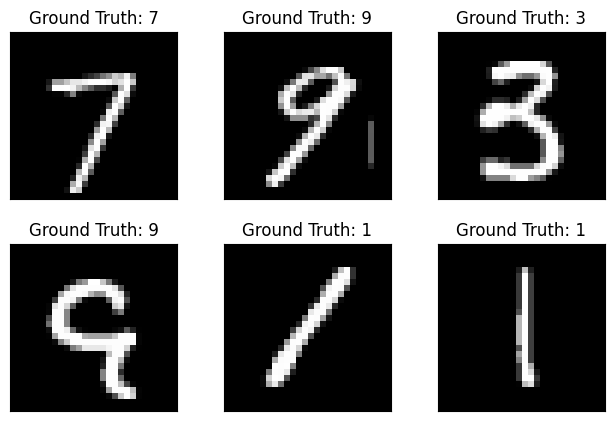

In [118]:
import matplotlib.pyplot as plt

fig = plt.figure()
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.tight_layout()
    plt.imshow(data[i][0], cmap='gray', interpolation='none')
    plt.title("Ground Truth: {}".format(targets[i]))
    plt.xticks([])
    plt.yticks([])

## A short PyTorch primer (before you build the network)

Before training the MNIST network, here is a small bridge from the manual math above to PyTorch. Three ideas: **tensors**, **autograd**, and **`nn.Module`**.

### Tensors
A `torch.Tensor` is an n-dimensional array (like a NumPy array) that PyTorch can also differentiate through. You create tensors, inspect their `.shape`, do elementwise math, and reshape/flatten them.

In [119]:
import torch

# Create a tensor (2 rows, 3 columns)
A = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print(A.shape)          # -> torch.Size([2, 3])

# Elementwise operations work like NumPy
print(A * 2)            # every entry doubled
print(A + A)            # elementwise sum

# A mini-batch of 64 MNIST images has shape (64, 1, 28, 28).
# For a Linear layer we flatten each image to a length-784 vector:
batch = torch.zeros(64, 1, 28, 28)
flat = torch.flatten(batch, 1)   # keep dim 0 (the batch), flatten the rest
print(flat.shape)       # -> torch.Size([64, 784])

torch.Size([2, 3])
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
torch.Size([64, 784])


### Autograd: let PyTorch reproduce your Part 1 gradients

In Part 1 you computed, by hand, $\partial E/\partial w^{(2)}_2 = -0.3253$ and $\partial E/\partial w^{(1)}_{2,2} = -0.1883$. PyTorch can do this automatically: mark the weight tensors with `requires_grad=True`, redo the forward pass, and call `E.backward()`. The gradients then appear in `W1.grad` and `w2.grad`.

Complete the cell below and confirm autograd reproduces your hand-derived numbers (`w2.grad[2] == -0.3253`, `W1.grad[2, 1] == -0.1883`; the hidden delta is $\delta_2 = -0.9416$).

One more piece of the bridge, for the training loop below: `optimizer.zero_grad()` resets the stored gradients before each batch (PyTorch otherwise *accumulates* gradients across `backward()` calls), and `optimizer.step()` applies the Part 1.4 update $w \leftarrow w - \eta \nabla E$ to every parameter of the model.

In [120]:
# Same example as Part 1, now with gradient tracking turned on
x = torch.tensor([[0.1],
                  [0.2]])
W1 = torch.tensor([[ 0.1, 0.2],
                   [-1.1, 1.2],
                   [-2.1, 2.2]], requires_grad=True)
w2 = torch.tensor([[-0.1],
                   [ 1.1],
                   [ 2.2]], requires_grad=True)

def augment(v):
    return torch.cat([torch.ones(1).unsqueeze(0), v])

# Forward pass (recomputed for you)
a = W1.t().mm(augment(x))
z = torch.nn.functional.relu(a)
y = w2.t().mm(augment(z))
t = torch.tensor([2])
E = 0.5 * (y - t)**2

# TODO: back-propagate the error and read off the gradients.
#       Call E.backward(), then print W1.grad and w2.grad.
#       Check: w2.grad[2] == -0.3253 and W1.grad[2, 1] == -0.1883.
E.backward()
print("W1.grad =", W1.grad, sep="\n")
print("w2.grad =", w2.grad, sep="\n")

W1.grad =
tensor([[ 0.0000, -0.9416],
        [ 0.0000, -0.0942],
        [ 0.0000, -0.1883]])
w2.grad =
tensor([[-0.4280],
        [-0.0000],
        [-0.3253]])


## 2.1) Create and train a 2-layer MLP
For the network, use a single hidden layer of 512 neurons with a ReLU activation function for the first weight Linear layer. The output of the second Linear layer should be turned into log-probabilities with `log_softmax` (over `dim=1`), so it pairs correctly with the negative log-likelihood loss (`nll_loss`). Note: applying `log_softmax` and then `nll_loss` is equivalent to using `CrossEntropyLoss` directly on the raw logits (unnormalised scores).

For optimisation, use the SGD optimizer with learning rate of 0.001, and the negative log-likelihood loss.

Train the network for 5 epochs on the train data, and report the prediction accuracy on the test data. You should be able to get about 90% correct.

Hint: check the [PyTorch documentation](https://pytorch.org/docs/stable/index.html) for usage of the layers, optimizers and losses

For this part of the exercise, you will want to replace each "REPLACE" with code corresponding to the task described in the line above it — such as "#Initialise Linear Layers", followed by "REPLACE", where you'd replace REPLACE with the code that initialises the linear layers.

In [121]:
from torch.nn import Linear, Module
from torch.nn.functional import relu, log_softmax, nll_loss
from torch.optim import SGD

class Net(Module):
    def __init__(self):
        super(Net, self).__init__()
        # fc1 is given as a worked example: it maps a flattened
        # 28*28 = 784 vector to 512 hidden units.   (N, 784) -> (N, 512)
        self.fc1 = Linear(28*28, 512)
        # TODO: fc2 maps the 512 hidden units to the 10 class scores.
        #       (N, 512) -> (N, 10)
        self.fc2 = Linear(512, 10)

    def forward(self, x):
        x = torch.flatten(x, 1)      # (N, 1, 28, 28) -> (N, 784)
        x = relu(self.fc1(x))        # (N, 784) -> (N, 512)
        # TODO: pass x through fc2 to get the class scores.   (N, 512) -> (N, 10)
        x = self.fc2(x)
        # TODO: return log-probabilities via log_softmax over dim=1
        #       (this is what pairs with nll_loss).   (N, 10) -> (N, 10)
        output = log_softmax(x, dim=1)
        return output

    
def train(
    model:Module, 
    train_loader:DataLoader, 
    optimizer: SGD, 
    epoch:int, 
    log_interval = 50
):
    # Set model to train mode
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # Reset the gradients
        optimizer.zero_grad()
        
        # Feed the data through the model
        output = model(data)
        
        # Compute the negative log-likelihood loss (store it in `loss`)
        loss = nll_loss(output, target)
        
        # Backward propagate the gradients
        loss.backward()
        
        # Perform an update step using the optimizer
        optimizer.step()
        
        # Log the training progress. This print is provided (using `loss` from
        # the step above) so the loop always has a body and runs as-is.
        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))
        


def test(model:Module, test_loader:DataLoader):
    # Set model to evaluation mode
    model.eval()
    
    test_loss = 0
    correct = 0
    
    # Don't accumulate gradients
    with torch.no_grad():
        for data, target in test_loader:
            # Feed the data through the model
            output = model(data)
            
            # Sum up the batch loss (use nll_loss(..., reduction='sum').item())
            test_loss += nll_loss(output, target, reduction='sum').item()
            
            # Predict the class (it is the index of the max log-probability)
            pred = output.argmax(dim=1)
            
            # Add to the number of correct
            correct += (pred == target).sum().item()
            
    test_loss /= len(test_loader.dataset)

    # Print results
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss,
        correct, 
        len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)
    ))


In [122]:
torch.manual_seed(0)   # reproducible weight init and shuffling
model = Net()
optimizer = SGD(model.parameters(), lr=0.001)

epochs = 5
for epoch in range(1, epochs + 1):
    train(model, train_loader, optimizer, epoch, log_interval=50)
    test(model, test_loader)

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.320454
Train Epoch: 1 [3200/60000 (5%)]	Loss: 2.228389
Train Epoch: 1 [6400/60000 (11%)]	Loss: 2.076245
Train Epoch: 1 [9600/60000 (16%)]	Loss: 1.922027
Train Epoch: 1 [12800/60000 (21%)]	Loss: 1.872729
Train Epoch: 1 [16000/60000 (27%)]	Loss: 1.799174
Train Epoch: 1 [19200/60000 (32%)]	Loss: 1.735156
Train Epoch: 1 [22400/60000 (37%)]	Loss: 1.582029
Train Epoch: 1 [25600/60000 (43%)]	Loss: 1.501521
Train Epoch: 1 [28800/60000 (48%)]	Loss: 1.521197
Train Epoch: 1 [32000/60000 (53%)]	Loss: 1.341674
Train Epoch: 1 [35200/60000 (59%)]	Loss: 1.334816
Train Epoch: 1 [38400/60000 (64%)]	Loss: 1.186054
Train Epoch: 1 [41600/60000 (69%)]	Loss: 1.262058
Train Epoch: 1 [44800/60000 (75%)]	Loss: 1.068285
Train Epoch: 1 [48000/60000 (80%)]	Loss: 1.141104
Train Epoch: 1 [51200/60000 (85%)]	Loss: 1.116801
Train Epoch: 1 [54400/60000 (91%)]	Loss: 1.004682
Train Epoch: 1 [57600/60000 (96%)]	Loss: 1.069403

Test set: Average loss: 0.9177, Accuracy: 8255/10000 (83%)